# Economic design of an X-bar chart

This notebook is a reproducible entry point to the captured simulator experiment. Run from this repository after installing requirements.txt. The collection step is separate and requires a new login for each replication. See README.md for the current evidence status. No synthetic data are substituted for simulator runs.

In [1]:
from pathlib import Path
import pandas as pd
import json
from IPython.display import display, Image
from control_chart_economic_design.analysis import analyze
analyze.main()
from control_chart_economic_design.analysis import supplement
supplement.main()
R = Path("results")

Matplotlib is building the font cache; this may take a moment.


{
  "runs": 55,
  "plans": 15,
  "best_base_cost": "n8-h2592-L2.5-R",
  "cost_regions": [
    {
      "ratio_low": 2.0,
      "ratio_high": 4.733021912320905,
      "winner": "n8-h2592-L3.5-S"
    },
    {
      "ratio_low": 4.733021912320905,
      "ratio_high": 50.0,
      "winner": "n8-h2592-L2.5-R"
    }
  ],
  "tests": [
    {
      "experiment": "A160",
      "n_runs": 15,
      "F": 1.9687720536344413,
      "p_anova": 0.17550534348565636,
      "p_kruskal": 0.2038362183277249,
      "p_shapiro_residuals": 0.39955295623668574,
      "p_levene": 0.8784452813977954
    },
    {
      "experiment": "A80",
      "n_runs": 12,
      "F": 3.95733800862006,
      "p_anova": 0.05316168413094187,
      "p_kruskal": 0.0922251223248706,
      "p_shapiro_residuals": 0.5372563857390554,
      "p_levene": 0.8770367717730805
    },
    {
      "experiment": "B",
      "n_runs": 15,
      "F": 3.312839808108364,
      "p_anova": 0.07151789222778353,
      "p_kruskal": 0.11417761691083628,
     

{
  "experiment_runs": 55,
  "production_days": 825,
  "chart_subgroups": 17459,
  "quality_records": 184503,
  "baseline_individuals": 600,
  "duplicate_output_pairs": 0,
  "signal_count_mismatches": 0,
  "timestamp_mismatches": 0,
  "max_budget_deviation_percent": 2.666666666666684
}


## Provenance and baseline
Each CSV row is one independent-login, 15-day run. Limits come from the same three-run Phase 1 pool for every candidate.

,mu,sigma,range_sigma,shapiro_individuals_p,shapiro_means_p,subgroups,individuals,lag1_means
0,0.050474,0.000522,0.000515,0.394667,0.384531,120,600,-0.008128


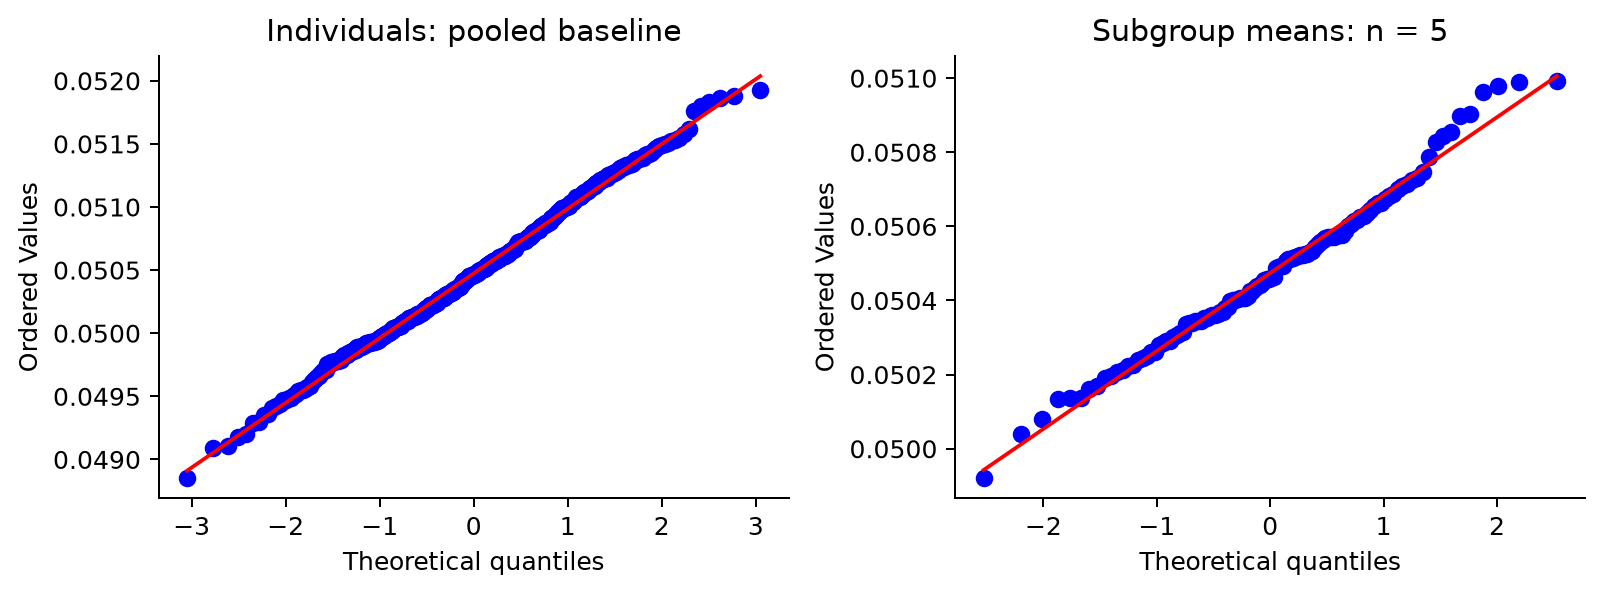

,run_id,production_days,quality_rows,chart_rows,signal_difference,timestamp_mismatch
0,A160_n10_r1,15,3377,240,0,0
1,A160_n10_r2,15,3266,240,0,0
2,A160_n10_r3,15,3293,241,0,0
3,A160_n2_r1,15,3426,1232,0,0
4,A160_n2_r2,15,3433,1229,0,0
5,A160_n2_r3,15,3294,1229,0,0
6,A160_n4_r1,15,3293,608,0,0
7,A160_n4_r2,15,3390,607,0,0
8,A160_n4_r3,15,3380,608,0,0
9,A160_n5_r1,15,3353,483,0,0


In [2]:
display(pd.DataFrame([json.loads((R/"baseline_diagnostics.json").read_text())]))
display(Image("figures/baseline_qq.png"))
display(pd.read_csv(R/"validation.csv"))

## Allocation and inspection effort
The horizontal axis is observed effort, not a requested budget. Error bars use replication-level means. Three replications give imprecise uncertainty estimates.

,run_id,n,h,L,method,units_per_day,bad_per_day,signals
0,A160_n10_r1,10,1440,3.0,Snapshot,160.000000,138.800000,1
1,A160_n10_r2,10,1440,3.0,Snapshot,160.000000,135.133333,0
2,A160_n10_r3,10,1440,3.0,Snapshot,160.666667,134.866667,0
3,A160_n2_r1,2,288,3.0,Snapshot,164.266667,139.733333,1
4,A160_n2_r2,2,288,3.0,Snapshot,163.866667,137.866667,6
5,A160_n2_r3,2,288,3.0,Snapshot,163.866667,132.400000,6
6,A160_n4_r1,4,576,3.0,Snapshot,162.133333,134.866667,1
7,A160_n4_r2,4,576,3.0,Snapshot,161.866667,136.466667,1
8,A160_n4_r3,4,576,3.0,Snapshot,162.133333,138.466667,1
9,A160_n5_r1,5,720,3.0,Snapshot,161.000000,133.533333,2


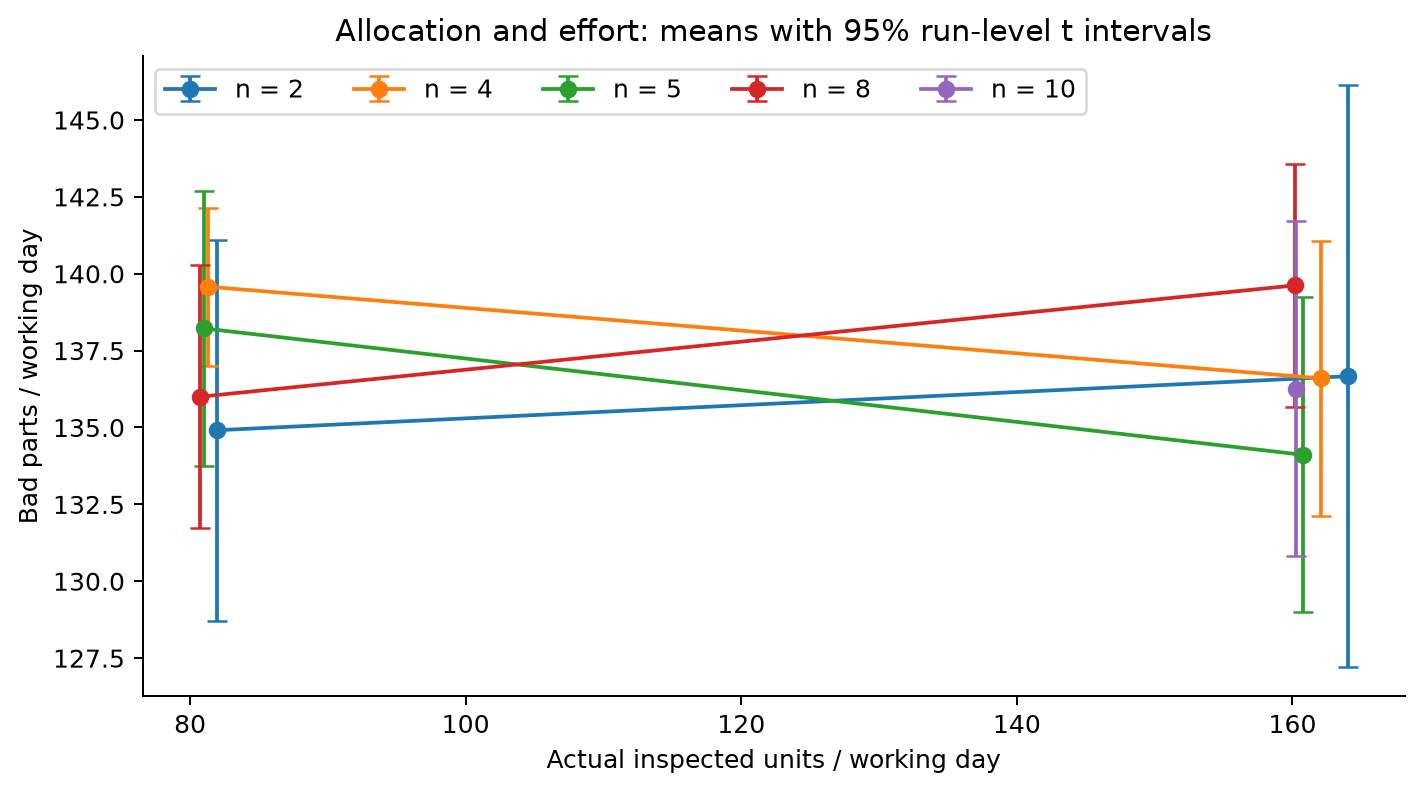

,experiment,n_runs,F,p_anova,p_kruskal,p_shapiro_residuals,p_levene
0,A160,15,1.968772,0.175505,0.203836,0.399553,0.878445
1,A80,12,3.957338,0.053162,0.092225,0.537256,0.877037
2,B,15,3.312840,0.071518,0.114178,0.895356,0.547474
3,C,10,4.519960,0.066202,0.117185,0.604039,0.934304


In [3]:
runs = pd.read_csv(R/"run_table.csv")
display(runs[["run_id","n","h","L","method","units_per_day","bad_per_day","signals"]])
display(Image("figures/quality_effort.png"))
display(pd.read_csv(R/"tests.csv"))

## Cost map and uncertainty
Unit inspection cost is fixed at $0.50. The chart varies bad-part cost only. The primary false-alarm charge is a model expectation, not observed truth.

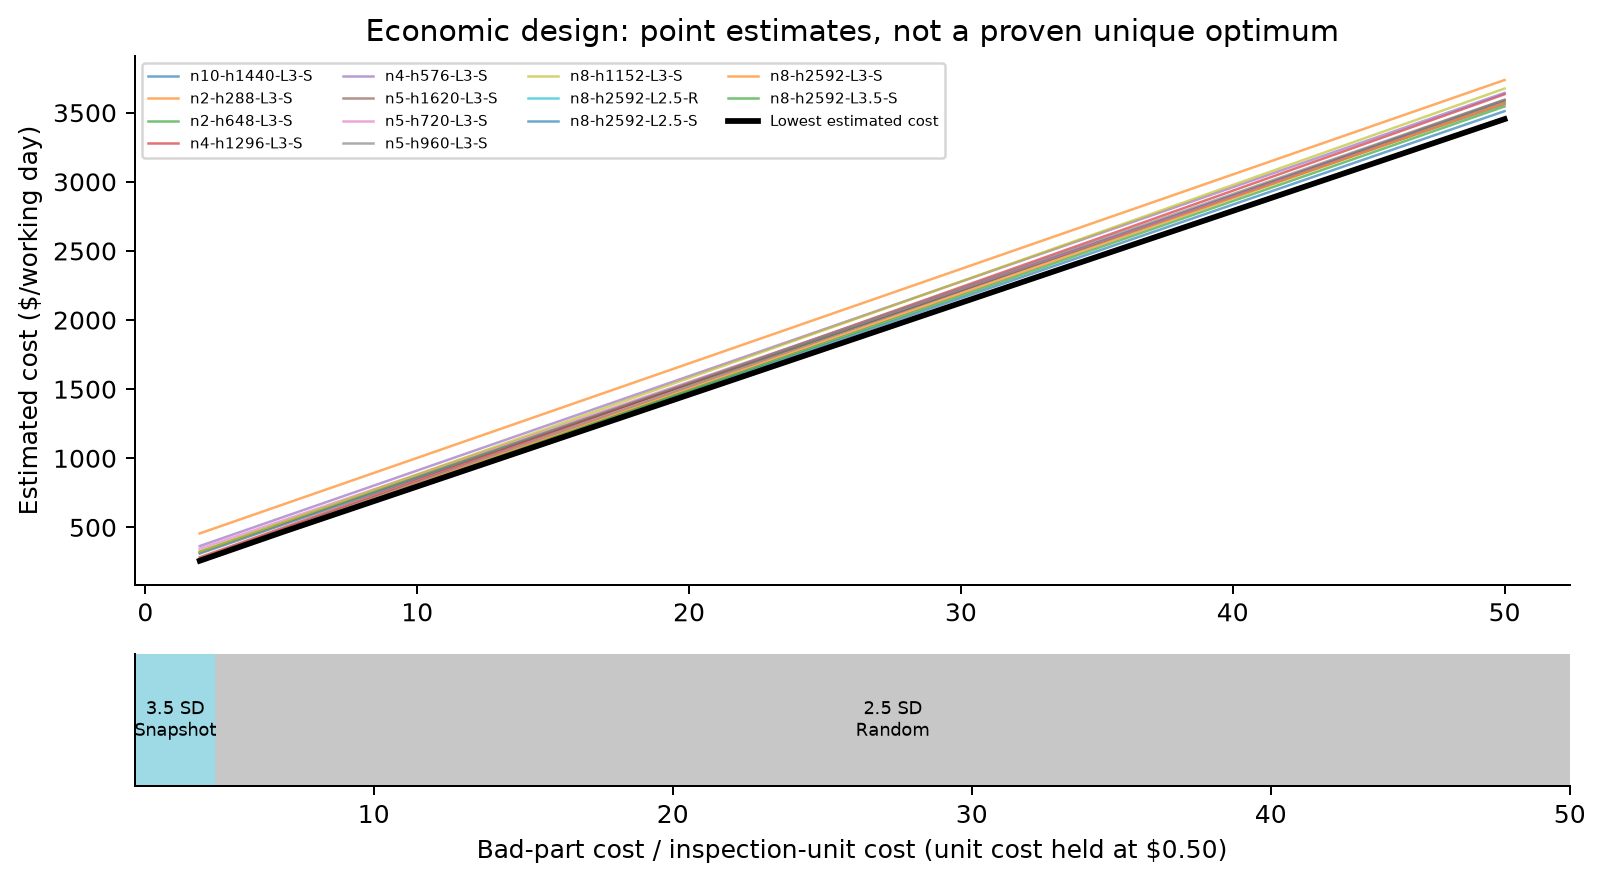

,ratio_low,ratio_high,winner
0,2.000000,4.733022,n8-h2592-L3.5-S
1,4.733022,50.000000,n8-h2592-L2.5-R


ratio,2,5,10,20,30,40,50
plan,,,,,,,
n10-h1440-L3-S,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
n2-h288-L3-S,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
n2-h648-L3-S,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
n4-h1296-L3-S,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
n4-h576-L3-S,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
n5-h1620-L3-S,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
n5-h720-L3-S,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
n5-h960-L3-S,0.00000,0.00000,0.00000,0.00000,0.00000,0.00025,0.00100
n8-h1152-L3-S,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000


,scenario,ratio,winner,cost
0,zero_false_alarm_cost,2,n8-h2592-L2.5-R,257.706667
1,zero_false_alarm_cost,10,n8-h2592-L2.5-R,789.280000
2,zero_false_alarm_cost,50,n8-h2592-L2.5-R,3447.146667
3,all_signals_charged,2,n8-h2592-L3.5-S,258.320000
4,all_signals_charged,10,n8-h2592-L2.5-R,793.280000
5,all_signals_charged,50,n8-h2592-L2.5-R,3451.146667
6,all_in_control_model,2,n8-h2592-L3.5-S,258.552939
7,all_in_control_model,10,n8-h2592-L2.5-R,795.646977
8,all_in_control_model,50,n8-h2592-L2.5-R,3453.513644


In [4]:
display(Image("figures/cost_map.png"))
display(pd.read_csv(R/"cost_regions_exact.csv"))
display(pd.read_csv(R/"bootstrap_winners.csv").pivot(index="plan",columns="ratio",values="bootstrap_win_probability"))
display(pd.read_csv(R/"false_alarm_cost_sensitivity.csv"))

## ARL and estimated onsets
A signal is not a known true detection. Onset estimates are conditional and censored. A uniformly placed shift has mean delay h*(ARL1-0.5), whereas a shift immediately after a sample has h*ARL1.

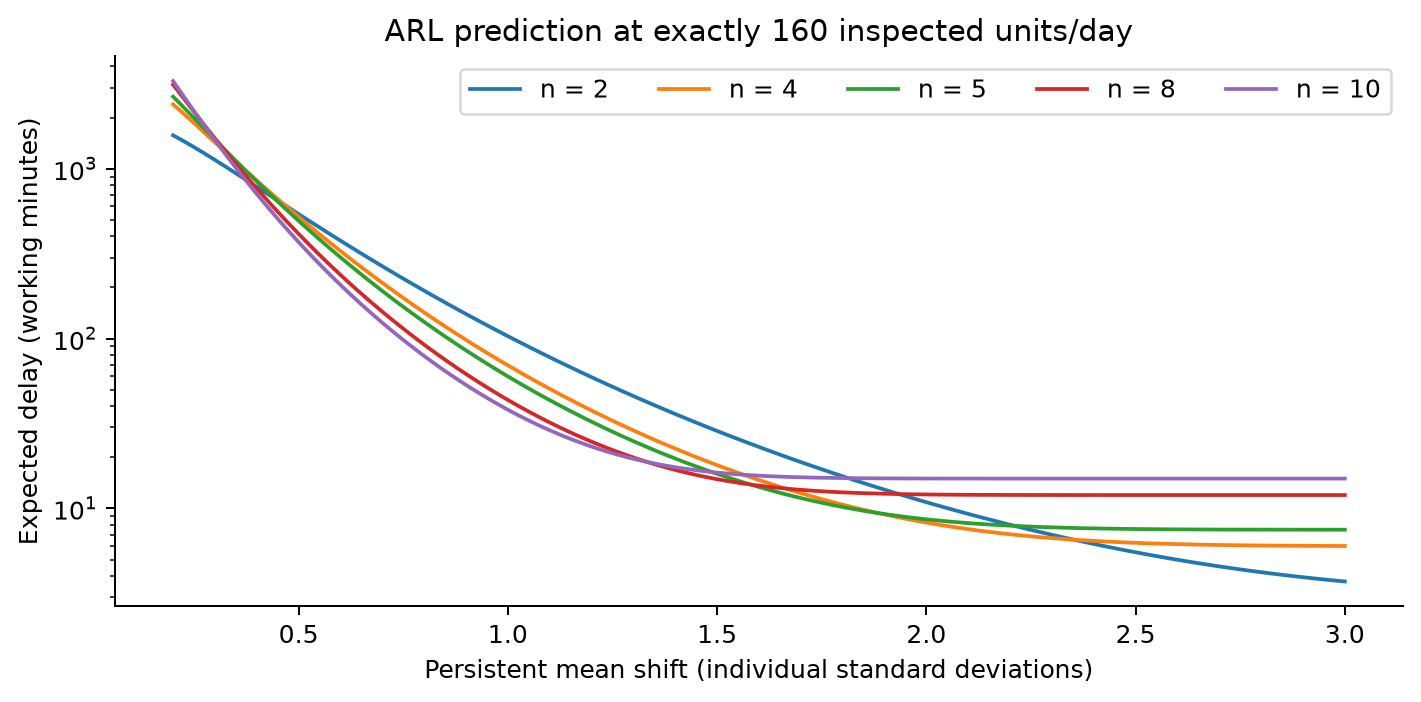

,run_id,signal_index,signal_time,classification,pre_signal_points,score,delta_hat,onset_index,delay_lower_seconds,delay_upper_seconds,window_left_censored,effective_h_seconds
0,A160_n10_r1,219,2026-11-12 14:36:57,unclassified,20,1.711393,NaN,NaN,NaN,NaN,False,1819.0
1,A160_n2_r1,139,2026-10-27 14:37:56,unclassified,20,1.093457,NaN,NaN,NaN,NaN,False,350.0
2,A160_n2_r2,180,2026-10-28 09:40:52,unclassified,20,0.554202,NaN,NaN,NaN,NaN,False,351.0
3,A160_n2_r2,265,2026-10-29 09:57:03,unclassified,20,2.632802,NaN,NaN,NaN,NaN,False,351.0
4,A160_n2_r2,330,2026-10-30 08:06:44,unclassified,20,0.816260,NaN,NaN,NaN,NaN,False,351.0
5,A160_n2_r2,594,2026-11-04 09:53:15,unclassified,20,0.522316,NaN,NaN,NaN,NaN,False,351.0
6,A160_n2_r2,805,2026-11-06 15:39:34,unclassified,20,2.064868,NaN,NaN,NaN,NaN,False,351.0
7,A160_n2_r2,1096,2026-11-12 11:03:31,unclassified,20,2.622375,NaN,NaN,NaN,NaN,False,351.0
8,A160_n2_r3,235,2026-10-28 15:54:34,unclassified,20,1.938959,NaN,NaN,NaN,NaN,False,353.0
9,A160_n2_r3,636,2026-11-04 15:08:31,unclassified,20,3.384895,NaN,NaN,NaN,NaN,False,353.0


,delta,shifts_per_in_control_day,excess_bad_per_out_of_control_day,ratio,n,budget,h,L,incremental_cost
0,0.5,0.1,10,2,10,40,7200.0,3.0,30.768259
1,0.5,0.1,10,10,10,40,7200.0,2.5,35.841449
2,0.5,0.1,10,50,10,40,7200.0,2.5,58.392032
3,0.5,0.1,50,2,10,40,7200.0,2.5,35.841449
4,0.5,0.1,50,10,10,40,7200.0,2.5,58.392032
5,0.5,0.1,50,50,10,80,3600.0,2.5,135.351749
6,0.5,0.1,100,2,10,40,7200.0,2.5,41.479095
7,0.5,0.1,100,10,10,40,7200.0,2.5,86.580261
8,0.5,0.1,100,50,10,120,2400.0,2.5,192.746495
9,0.5,0.5,10,2,10,40,7200.0,2.5,33.404125


In [5]:
display(Image("figures/arl_theory.png"))
display(pd.read_csv(R/"signal_events.csv"))
display(pd.read_csv(R/"renewal_sensitivity.csv").head(12))

## Corrected original lab result
Historical Welch tests use the reported means, SDs and sample sizes. They cannot test day-to-day dependence or recover the limits actually entered online.

In [6]:
display(pd.read_csv(R/"original_lab_welch.csv"))

,metric,lab6_mean,lab7_mean,difference,ci_low,ci_high,p,df,source
0,total,804.200,811.800,7.600,-10.672420,25.872420,4.010901e-01,27.289199,reported summary statistics; independent-day a...
1,good,599.200,631.333,32.133,11.330813,52.935187,4.044879e-03,22.691867,reported summary statistics; independent-day a...
2,bad,147.267,121.333,-25.934,-33.759816,-18.108184,2.283628e-07,27.926192,reported summary statistics; independent-day a...
3,offspec,57.733,59.133,1.400,-4.506795,7.306795,6.300949e-01,25.773523,reported summary statistics; independent-day a...


## Limitations
Read docs/METHODS.md and docs/original_lab_audit.md before using these findings. The simulator enforces corrective action; its outputs are not a real-plant validation. Actual cause times, false-alarm labels, hidden server seeds, and search/repair costs are unavailable. Sequential plan selection and shared baseline uncertainty are not fully represented in the bootstrap.